In [1]:
import tensorflow as tf
import numpy as np
import os
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

In [2]:
# load image
classes = os.listdir('./dataset/')
print(classes)
x = []
y = []
img_row = 102
img_col = 136
counter = 0

for folder_path in os.listdir('./dataset/'):
    for file_path in os.listdir(f'./dataset/{folder_path}'):
        picture_path = f"dataset/{folder_path}/{file_path}"
        image = tf.keras.preprocessing.image.load_img(picture_path, target_size=(img_row, img_col))
        image = tf.keras.preprocessing.image.img_to_array(image)
        x.append(image)
        y.append(counter)
        
    counter += 1
    


['Boot', 'Sandal', 'Shoe']


In [3]:
# preprocessing data
x = np.array(x)
y = np.array(y)

x = x.astype('float32') / 255.0

In [4]:
x[0]

array([[[1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.],
        ...,
        [1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.]],

       [[1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.],
        ...,
        [1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.]],

       [[1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.],
        ...,
        [1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.]],

       ...,

       [[1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.],
        ...,
        [1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.]],

       [[1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.],
        ...,
        [1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.]],

       [[1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.],
        ...,
        [1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.]]], dtype=float32)

In [5]:
print(classes[y[0]])

Boot


In [6]:
# split data
# train, validation, test
# 80:10:10

X_train, X_temp, y_train, y_temp = train_test_split(x, y, test_size=0.2, random_state=7)
X_test, X_val, y_test, y_val = train_test_split(X_temp, y_temp, test_size=0.5, random_state=37)

In [7]:
y_train = tf.keras.utils.to_categorical(y_train)
y_train[0]

array([0., 0., 1.], dtype=float32)

In [8]:
y_val = tf.keras.utils.to_categorical(y_val)
y_test = tf.keras.utils.to_categorical(y_test)

In [ ]:
# bikin model
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(img_row, img_col, 3)), # 3 karena RGB, bukan len(classes)
    tf.keras.layers.Conv2D(6, kernel_size=(5,5), activation='relu'),
    tf.keras.layers.AveragePooling2D(pool_size=(2,2), strides=1),
    tf.keras.layers.Conv2D(12, kernel_size=(5,5), activation='relu'),
    tf.keras.layers.AveragePooling2D(pool_size=(2,2), strides=1),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(3, activation='softmax') # output
])

In [10]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 98, 132, 6)        456       
                                                                 
 average_pooling2d (AverageP  (None, 97, 131, 6)       0         
 ooling2D)                                                       
                                                                 
 conv2d_1 (Conv2D)           (None, 93, 127, 12)       1812      
                                                                 
 average_pooling2d_1 (Averag  (None, 92, 126, 12)      0         
 ePooling2D)                                                     
                                                                 
 flatten (Flatten)           (None, 139104)            0         
                                                                 
 dense (Dense)               (None, 64)                8

In [11]:
model.compile(
    optimizer = tf.keras.optimizers.Adam(0.001),
    loss = 'categorical_crossentropy',
    metrics = ['Accuracy']
)

In [12]:
history = model.fit(X_train, y_train, epochs=5, batch_size=100, validation_data=(X_val, y_val))

Epoch 1/5
120/120 [==============================] - 10s 32ms/step - loss: 0.5264 - Accuracy: 0.8362 - val_loss: 0.1700 - val_Accuracy: 0.9447
Epoch 2/5
120/120 [==============================] - 4s 31ms/step - loss: 0.1526 - Accuracy: 0.9465 - val_loss: 0.1348 - val_Accuracy: 0.9540
Epoch 3/5
120/120 [==============================] - 4s 31ms/step - loss: 0.1105 - Accuracy: 0.9599 - val_loss: 0.1419 - val_Accuracy: 0.9500
Epoch 4/5
120/120 [==============================] - 4s 31ms/step - loss: 0.0831 - Accuracy: 0.9715 - val_loss: 0.1412 - val_Accuracy: 0.9540
Epoch 5/5
120/120 [==============================] - 4s 33ms/step - loss: 0.0500 - Accuracy: 0.9832 - val_loss: 0.1132 - val_Accuracy: 0.9567


In [13]:
evaluate = model.evaluate(X_test, y_test)
print("Loss: ", evaluate[0])
print("Accuracy: ", evaluate[1])

47/47 [==============================] - 0s 5ms/step - loss: 0.1794 - Accuracy: 0.9427
Loss:  0.17942075431346893
Accuracy:  0.9426666498184204


47/47 [==============================] - 0s 3ms/step


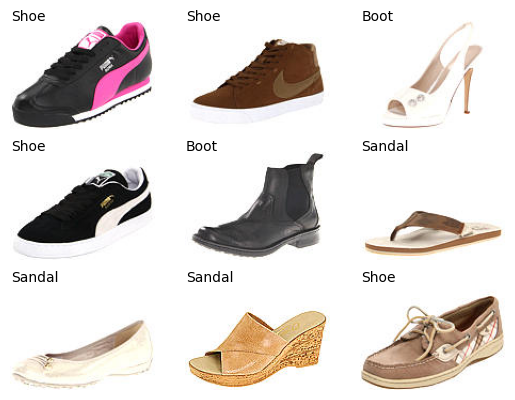

In [ ]:
predicted = model.predict(X_test)
predicted_label = np.argmax(predicted, axis=1)

for i in range(9):
    plt.subplot(3, 3, i+1)
    plt.imshow(X_test[i])
    plt.axis('off')
    plt.text(0.5, -0.15, classes[predicted_label[i]])

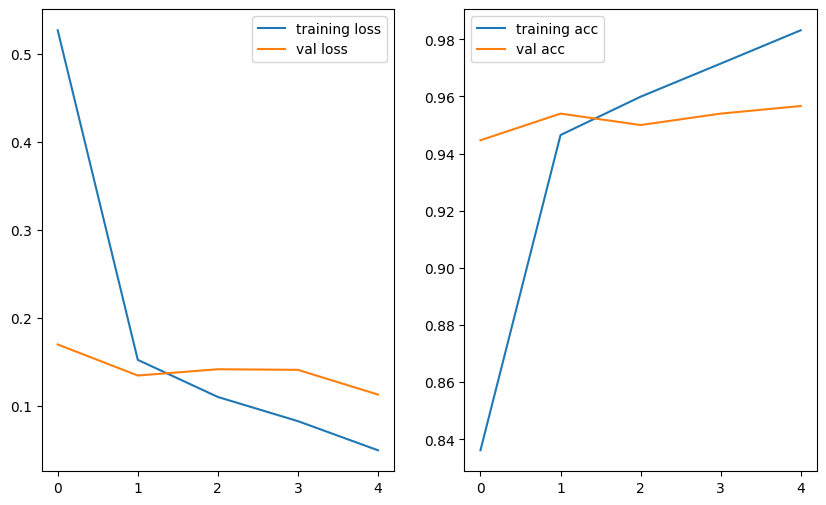

In [20]:
plt.figure(figsize=(10,6))
plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='training loss')
plt.plot(history.history['val_loss'], label='val loss')
plt.xlabel = 'epoch'
plt.ylabel = 'loss'
plt.title = 'Loss'
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['Accuracy'], label='training acc')
plt.plot(history.history['val_Accuracy'], label='val acc')
plt.xlabel = 'epoch'
plt.ylabel = 'acc'
plt.title = 'Acc'
plt.legend()


plt.show()
